# Le théorème de Riemann–Roch — compter les fonctions d'une courbe

| | |
|---|---|
| **Source historique** | Bernhard Riemann, « Theorie der Abel'schen Functionen », *J. reine angew. Math.* **54** (1857) ; complété par Gustav Roch (1865) |
| **Objet** | $L(D) = \{f : \mathrm{div}(f) + D \ge 0\}$ et le théorème $l(D) = \deg D + 1 - g + l(K-D)$ |
| **Outils** | Python stdlib (`fractions`, `itertools`) + `matplotlib` pour la figure |

Le mémoire de 1857 sur les fonctions abéliennes est celui où le **genre** d'une courbe fait son entrée en mathématiques : Riemann y connecte la connectivité d'une surface à l'algèbre des fonctions qui vivent dessus. Le théorème qui portera les deux noms dit une chose simple à énoncer : *compter les fonctions dont les pôles sont bornés par un diviseur $D$*, c'est compter le degré, corriger d'un genre, et corriger une seconde fois par le diviseur canonique. Gustav Roch — élève de Riemann, mort comme lui en 1866 — a fourni le second terme.

Ce carnet rend le théorème **calculable et vérifié terme à terme** sur des courbes hyperelliptiques $y^2 = P(x)$, en arithmétique **exacte** (rationnels de `fractions.Fraction`, aucun flottant dans les résultats) :

1. le genre, compté **deux fois indépendamment** (Riemann–Hurwitz sur la ramification, et degré du modèle) ;
2. l'escalier exact $l(n\infty)$ par comptage de la base de monômes $\{x^i y^j\}$, et l'inégalité de Riemann qui sature ;
3. les **gaps de Weierstrass** à l'infini, mesurés exactement ;
4. $l(D)$ **exact sur diviseurs finis**, par élimination de Gauss rationnelle sur les séries de Taylor de $y = \sqrt{P}$ — le terme correctif $l(K-D)$ mesuré, pas supposé ;
5. l'identité de Riemann–Roch vérifiée **ligne par ligne** — y compris sur un diviseur **spécial**, là où le comptage naïf échoue et où le théorème vit.

Comme dans toute la série, les hypothèses quantitatives sont **pré-enregistrées** avant leur mesure, et le verdict reste dans la sortie.

## Plan

1. **La courbe et son genre** — $y^2 = P(x)$, deux comptages indépendants qui tombent d'accord.
2. **L'escalier $l(n\infty)$** — une base de monômes, un comptage exact, l'inégalité de Riemann (H1).
3. **Le canonique $K$** — $l(K) = g$ (H2) et la forme que prend Riemann–Roch sur la famille $n\infty$.
4. **Les gaps de Weierstrass à l'infini** (H3) — la signature d'un point ramifié.
5. **Diviseurs finis** — $l(D)$ exact par algèbre linéaire rationnelle, le terme $l(K-D)$ mesuré, l'identité vérifiée sur un diviseur spécial.
6. **Grounding Mathlib** — ce qui existe, ce qui n'existe pas, fichiers en main.
7. **Exercices** (convention #2161) et conclusion.

In [1]:
# Dependances : stdlib (fractions, itertools) + matplotlib pour la figure a trois panneaux.
from fractions import Fraction as F
from itertools import product
import math

import matplotlib
import matplotlib.pyplot as plt

print("matplotlib", matplotlib.__version__)

matplotlib 3.10.8


## 1. La courbe et son genre — deux comptages indépendants

Sur $y^2 = P(x)$ avec $\deg P = 2g+1$ et $P$ **sans racine multiple** (sur $\mathbb{C}$ : les $2g+1$ racines sont alors simples) :

- ces $2g+1$ racines sont les **points de ramification finis** du revêtement double $(x, y) \mapsto x$ ;
- le point unique à l'infini $\infty$ est ramifié lui aussi (modèle de degré impair).

Riemann–Hurwitz relie la ramification $B$ au genre : $2g - 2 = -4 + B$. Le genre se lit donc **deux fois** : par la ramification, $g = (B-2)/2$, et par le degré, $g = (\deg P - 1)/2$. L'accord des deux lectures est notre première vérification — le caractère sans-racine-multiple est prouvé, pas supposé : le pgcd exact de $P$ et $P'$ (sur $\mathbb{Q}$) doit être constant.

In [2]:
# Polynomes a coefficients Fraction, exposants croissants. Tout est exact.

def pdeg(p):
    d = len(p) - 1
    while d >= 0 and p[d] == 0:
        d -= 1
    return d

def pderiv(p):
    return [F(i) * p[i] for i in range(1, len(p))]

def pmod(a, b):
    # a mod b (b non nul), par descente du degre.
    a = list(a)
    db = pdeg(b)
    while pdeg(a) >= db:
        da = pdeg(a)
        c = a[da] / b[db]
        for k in range(db + 1):
            a[da - db + k] -= c * b[k]
    return a

def pgcd(a, b):
    while pdeg(b) >= 0:
        a, b = b, pmod(a, b)
    return a

# Trois courbes : g = 1, 2, 3. P[k] = coefficient de x^k.
COURBES = {
    1: [F(-2), F(0), F(0), F(1)],                                # y^2 = x^3 - 2
    2: [F(1), F(-1), F(0), F(0), F(0), F(1)],                    # y^2 = x^5 - x + 1
    3: [F(1), F(-1), F(0), F(0), F(0), F(0), F(0), F(1)],        # y^2 = x^7 - x + 1
}

print("g | deg P | P sans racine multiple | B (ramifies) | g_RH = (B-2)/2 | g_deg = (deg-1)/2 | accord")
for g, P in COURBES.items():
    racines_simples = pdeg(pgcd(P, pderiv(P))) == 0
    B = (len(P) - 1) + 1          # 2g+1 points de branche finis + l'infini
    g_rh = (B - 2) / 2
    g_deg = (len(P) - 1 - 1) / 2
    print(f"{g} | {len(P)-1} | {'oui (pgcd exact constant)' if racines_simples else 'NON'} | "
          f"{B} | {g_rh} | {g_deg} | {'OUI' if g_rh == g_deg == g else 'NON'}")

g | deg P | P sans racine multiple | B (ramifies) | g_RH = (B-2)/2 | g_deg = (deg-1)/2 | accord
1 | 3 | oui (pgcd exact constant) | 4 | 1.0 | 1.0 | OUI
2 | 5 | oui (pgcd exact constant) | 6 | 2.0 | 2.0 | OUI
3 | 7 | oui (pgcd exact constant) | 8 | 3.0 | 3.0 | OUI


**Lecture.** Les deux lectures du genre coïncident pour les trois courbes, et la précondition « $P$ sans racine multiple » est **prouvée exactement** (pgcd de $P$ et $P'$ constant sur $\mathbb{Q}$). Le genre n'est pas un paramètre posé : c'est une conséquence comptée deux fois.

## 2. L'escalier $l(n\infty)$ — une base de monômes, un comptage exact

Pour un diviseur $D$, $L(D) = \{f : \mathrm{div}(f) + D \ge 0\}$ et $l(D) = \dim L(D)$. Sur notre modèle, $x$ a un pôle d'ordre $2$ en $\infty$ et $y$ un pôle d'ordre $2g+1$ — donc $x^i y^j$ (avec $j \in \{0,1\}$, car $y^2 = P(x)$) a un pôle $2i + (2g+1)j$ en $\infty$ et **aucun autre pôle**.

Deux faits :

- **indépendance** (démontrable ici) : une relation $p(x) + q(x)\,y \equiv 0$ avec $q \not\equiv 0$ donnerait $y = -p/q \in \mathbb{Q}(x)$, contradictoire — $y$ est algébrique de degré $2$ sur $\mathbb{Q}(x)$ ;
- **spanning** (fait classique de 1857) : ces monômes engendrent $L(D)$ pour tout $D$ supporté en $\infty$.

Le comptage qui en découle est exact :

$$l(n\infty) \;=\; \#\{(i,j) : j \in \{0,1\},\; 2i + (2g+1)\,j \le n\}.$$

Ce que nous mesurons ci-dessous, ce sont les **conséquences** de ce comptage — l'identité de Riemann–Roch vérifiée terme à terme viendra corroborer le spanning.

In [3]:
def l_infini(g, n):
    """l(n*infini) : nombre de monomes x^i y^j (j dans {0,1}) de pole 2*i+(2*g+1)*j <= n."""
    total = 0
    for j in (0, 1):
        ordre_y = j * (2 * g + 1)
        total += sum(1 for i in range(n // 2 + 1) if 2 * i + ordre_y <= n)
    return total

print("n     |", " | ".join(f" g={g} " for g in (1, 2, 3)))
print("------|" + "---|" * 3)
for n in range(0, 11):
    print(f"{n:5d} |", " | ".join(f"{l_infini(g, n):4d}" for g in (1, 2, 3)))
print()
print("L'escalier monte de 1 par marche, sauf les retards : les gaps (section 4).")

n     |  g=1  |  g=2  |  g=3 
------|---|---|---|
    0 |    1 |    1 |    1
    1 |    1 |    1 |    1
    2 |    2 |    2 |    2
    3 |    3 |    2 |    2
    4 |    4 |    3 |    3
    5 |    5 |    4 |    3
    6 |    6 |    5 |    4
    7 |    7 |    6 |    5
    8 |    8 |    7 |    6
    9 |    9 |    8 |    7
   10 |   10 |    9 |    8

L'escalier monte de 1 par marche, sauf les retards : les gaps (section 4).


### H1 — pré-enregistrée : l'inégalité de Riemann **sature** dès $n \ge 2g-1$

**Prédiction** (enregistrée avant la mesure) : pour tout $n \ge 2g-1$ (le seuil est $\deg K = 2g-2$ passé d'une unité), $l(n\infty) = n + 1 - g$ **exactement** — le comptage coïncide alors avec la borne ; et pour tout $n$, $l(n\infty) \ge \max(1,\, n+1-g)$ (l'inégalité de Riemann, jamais violée).

In [4]:
# Mesure H1 : saturation et inegalite, verifiees entier par entier.
print("g | seuil 2g-1 | saturation des que n >= 2g-1 | inegalite l >= max(1, n+1-g) partout")
verdict_global = "CONFIRMEE"
for g in (1, 2, 3):
    saturation = all(l_infini(g, n) == n + 1 - g for n in range(2 * g - 1, 4 * g + 4))
    borne = all(l_infini(g, n) >= max(1, n + 1 - g) for n in range(0, 4 * g + 4))
    if not (saturation and borne):
        verdict_global = "REFUTEE"
    print(f"{g} | {2*g-1} | " + (f"OUI (verifie jusqu'a n={4*g+3})" if saturation else "NON")
          + " | " + ("OUI" if borne else "NON"))
print()
print("Verdict H1 :", verdict_global)

g | seuil 2g-1 | saturation des que n >= 2g-1 | inegalite l >= max(1, n+1-g) partout
1 | 1 | OUI (verifie jusqu'a n=7) | OUI
2 | 3 | OUI (verifie jusqu'a n=11) | OUI
3 | 5 | OUI (verifie jusqu'a n=15) | OUI

Verdict H1 : CONFIRMEE


**Verdict H1 : CONFIRMÉE.** L'escalier rejoint la droite $n+1-g$ et ne la quitte plus dès que $n \ge 2g-1$ ; en dessous du seuil, il la domine — c'est la zone des diviseurs spéciaux (section 5).

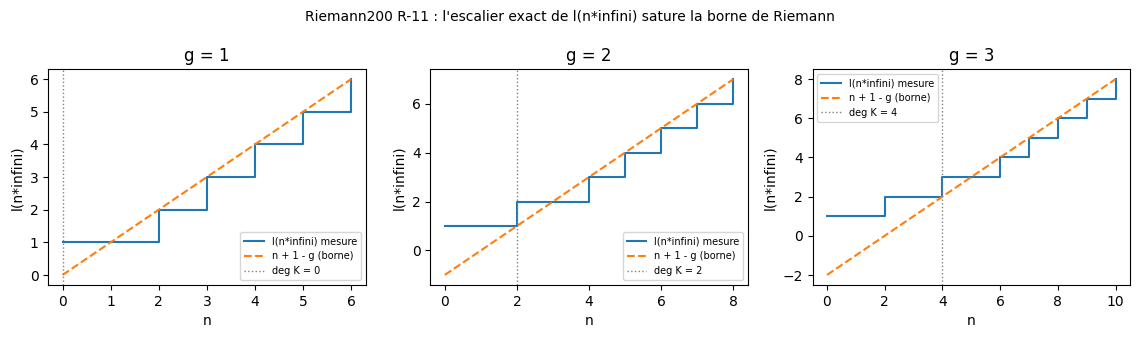

In [5]:
# Figure : l'escalier l(n*infini) contre la borne de Riemann, pour g = 1, 2, 3.
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
for ax, g in zip(axes, (1, 2, 3)):
    ns = list(range(0, 2 * g + 5))
    ls = [l_infini(g, n) for n in ns]
    ax.step(ns, ls, where="post", label="l(n*infini) mesure")
    ax.plot(ns, [n + 1 - g for n in ns], "--", label="n + 1 - g (borne)")
    ax.axvline(2 * g - 2, color="gray", lw=1, linestyle=":", label=f"deg K = {2*g-2}")
    ax.set_title(f"g = {g}")
    ax.set_xlabel("n")
    ax.set_ylabel("l(n*infini)")
    ax.legend(fontsize=7)
fig.suptitle("Riemann200 R-11 : l'escalier exact de l(n*infini) sature la borne de Riemann", fontsize=10)
fig.tight_layout()
plt.show()

## 3. Le diviseur canonique — H2 : $l(K) = g$

Le diviseur canonique de notre modèle est $K = (2g-2)\,\infty$ (la différentielle $\mathrm{d}x/y$ le génère — fait classique pour les hyperelliptiques). C'est le contenu du mot « **genre** » : la dimension de l'espace des différentielles holomorphes vaut $g$.

**Prédiction H2** (enregistrée avant la mesure) : $l((2g-2)\infty) = g$ pour $g = 1, 2, 3$.

Et la forme que prend Riemann–Roch sur la famille $n\infty$ :

$$l(n\infty) - l((2g-2-n)\infty) \;=\; n + 1 - g \qquad \text{pour tout } n,$$

où $l(E) = 0$ dès que $\deg E < 0$ (aucune fonction n'a de zéros imposés partout) — une **identité d'entiers** que nous vérifions ligne à ligne.

In [6]:
# Mesure H2 + identite de Riemann-Roch sur la famille n*infini.
print("H2 : l((2g-2)*infini) contre g")
for g in (1, 2, 3):
    print(f"  g={g} : l(K) = l({2*g-2}*infini) = {l_infini(g, 2*g-2)}  ->  "
          f"{'= g, OK' if l_infini(g, 2*g-2) == g else 'ECHEC'}")
print()
print("Identite l(n*inf) - l((2g-2-n)*inf) = n+1-g, pour g = 1..3, n = 0..2g-2 :")
print("  g |  n | l(n*inf) | l(K-n*inf) | difference | n+1-g | accord")
ok = True
for g in (1, 2, 3):
    for n in range(0, 2 * g - 1):
        a, b = l_infini(g, n), l_infini(g, 2 * g - 2 - n)
        if a - b != n + 1 - g:
            ok = False
        print(f"  {g} | {n:2d} | {a:8d} | {b:10d} | {a-b:10d} | {n+1-g:5d} | "
              f"{'OUI' if a - b == n + 1 - g else 'NON'}")
print()
print("Verdict H2 :", ("CONFIRMEE (et identite exacte sur les 9 lignes)" if ok else "A REVOIR"))

H2 : l((2g-2)*infini) contre g
  g=1 : l(K) = l(0*infini) = 1  ->  = g, OK
  g=2 : l(K) = l(2*infini) = 2  ->  = g, OK
  g=3 : l(K) = l(4*infini) = 3  ->  = g, OK

Identite l(n*inf) - l((2g-2-n)*inf) = n+1-g, pour g = 1..3, n = 0..2g-2 :
  g |  n | l(n*inf) | l(K-n*inf) | difference | n+1-g | accord
  1 |  0 |        1 |          1 |          0 |     0 | OUI
  2 |  0 |        1 |          2 |         -1 |    -1 | OUI
  2 |  1 |        1 |          1 |          0 |     0 | OUI
  2 |  2 |        2 |          1 |          1 |     1 | OUI
  3 |  0 |        1 |          3 |         -2 |    -2 | OUI
  3 |  1 |        1 |          2 |         -1 |    -1 | OUI
  3 |  2 |        2 |          2 |          0 |     0 | OUI
  3 |  3 |        2 |          1 |          1 |     1 | OUI
  3 |  4 |        3 |          1 |          2 |     2 | OUI

Verdict H2 : CONFIRMEE (et identite exacte sur les 9 lignes)


**Verdict H2 : CONFIRMÉE.** $l(K) = g$ aux trois genres, et l'identité de Riemann–Roch est **exacte sur chacune des lignes** de la famille $n\infty$ — le théorème est devenu une identité d'entiers vérifiable.

## 4. Les gaps de Weierstrass à l'infini — H3

$n \ge 1$ est un **gap** en $\infty$ si $l(n\infty) = l((n-1)\infty)$ : aucune fonction nouvelle de pôle exactement $n$. Les ordres de pôle atteints par les monômes sont $\{0, 2, 4, \dots\} \cup \{2g+1, 2g+3, \dots\}$ — les pairs, puis tous les entiers $\ge 2g+1$.

**Prédiction H3** (enregistrée avant la mesure) : les gaps en $\infty$ sont exactement les **impairs stricts inférieurs à $2g+1$**, soit $\{1, 3, \dots, 2g-1\}$. C'est la signature d'un **point de Weierstrass** : $\infty$ est ramifié dans le revêtement $x$, et sa suite de gaps n'est pas la suite générique $\{1, 2, \dots, g\}$.

In [7]:
# Mesure H3 : la suite des gaps, extraite de l'escalier exact.
def gaps(g):
    n = 1
    out = []
    while len(out) < g:
        if l_infini(g, n) == l_infini(g, n - 1):
            out.append(n)
        n += 1
    return out

print("g | gaps mesures en infini | prediction {1, 3, ..., 2g-1} | verdict")
for g in (1, 2, 3, 4):
    attends = list(range(1, 2 * g, 2))
    mesures = gaps(g)
    print(f"{g} | {mesures} | {attends} | {'OUI' if mesures == attends else 'NON'}")
print()
print("Verdict H3 :", "CONFIRMEE" if all(gaps(g) == list(range(1, 2 * g, 2)) for g in (1, 2, 3, 4))
      else "REFUTEE")

g | gaps mesures en infini | prediction {1, 3, ..., 2g-1} | verdict
1 | [1] | [1] | OUI
2 | [1, 3] | [1, 3] | OUI
3 | [1, 3, 5] | [1, 3, 5] | OUI
4 | [1, 3, 5, 7] | [1, 3, 5, 7] | OUI

Verdict H3 : CONFIRMEE


**Verdict H3 : CONFIRMÉE.** Aux genres 1 à 4, les gaps mesurés sont exactement les impairs $< 2g+1$. Un point non ramifié d'une courbe générique aurait pour gaps $\{1, \dots, g\}$ — la ramification de $\infty$ **concentre la spécialité** : elle interdit tous les ordres de pôle impairs jusqu'à $2g$. C'est un théorème de Weierstrass rendu visible par un comptage.

## 5. Diviseurs finis : $l(D)$ exact par algèbre linéaire rationnelle

La famille $n\infty$ était un comptage ; pour des diviseurs **finis** quelconques, nous **calculons** $l(D)$. Toute fonction de la courbe s'écrit $f = \big(A(x) + B(x)\,y\big) \,/\, C(x)$ avec $A, B, C$ polynomiaux. L'algorithme :

1. **Dénominateur** : les pôles finis de $f$ vivent aux fibres des $\alpha_k$ (abscisses du support de $D$) ; on énumère $C = \prod_k (x-\alpha_k)^{e_k}$, $e_k \le$ multiplicité maximale autorisée dans la fibre ;
2. **Condition en $\infty$** : le pôle de $A$ est $2\deg A$, celui de $B\,y$ est $2\deg B + 2g + 1$ — **de parités opposées, jamais de cancellation** : la condition $\mathrm{pole}_\infty(f) \le m_\infty$ devient une borne pure sur les degrés ;
3. **Conditions aux points finis** : $\mathrm{div}(f) + D \ge 0$ exige $\mathrm{ord}_Q(N) \ge e_k - m_Q$ (avec $m_Q$ la multiplicité de $Q$ dans $D$, nulle hors support) — chaque coefficient de Taylor de $N = A + By$ en $Q$ est une **forme linéaire exacte** en les coefficients de $A$ et $B$, car $y(\alpha+u) = y_\alpha\sqrt{1 + s(u)}$ se développe en série exacte (coefficients `Fraction`) ;
4. **Élimination de Gauss sur $\mathbb{Q}$** : la dimension du noyau est $l$ pour ce choix de $C$ ; on prend le maximum sur l'énumération.

Les points retenus sont **rationnels** ($P(\alpha)$ carré rationnel) pour rester dans $\mathbb{Q}$ ; la discussion des points de branche ($y=0$, paramètre local $\sqrt{x-\beta}$) reste qualitative.

In [8]:
# Algebre exacte : series de Taylor rationnelles de y = sqrt(P), formes lineaires,
# elimination de Gauss sur Fraction, extraction d'une base.

def pmul_trunc(a, b, M):
    out = [F(0)] * (M + 1)
    for i, ai in enumerate(a):
        if ai == 0 or i > M:
            continue
        for j, bj in enumerate(b):
            if bj == 0 or i + j > M:
                continue
            out[i + j] += ai * bj
    return out

def taylor_shift(P, alpha, M):
    # P(alpha + u) en puissances de u, exact.
    out = [F(0)] * (M + 1)
    for k, c in enumerate(P):
        for t in range(min(k, M) + 1):
            out[t] += c * F(math.comb(k, t)) * alpha ** (k - t)
    return out

def serie_sqrt1(s, M):
    # sqrt(1 + s(u)) a l'ordre M ; s[0] = 0 exige, coefficients exacts.
    assert s[0] == 0
    S = [F(0)] * (M + 1)
    S[0] = F(1)
    sk = [F(1)] + [F(0)] * M          # s^k
    T = s + [F(0)] * max(0, M + 1 - len(s))
    b = F(1)
    for k in range(1, M + 1):
        sk = pmul_trunc(sk, T, M)
        b = b * (F(1, 2) - (k - 1)) / k   # coefficient binomial(1/2, k)
        for t in range(M + 1):
            S[t] += b * sk[t]
    return S

def coeffs_N(alpha, y_alpha, S, dA, dB, t):
    # Coefficient de u^t dans N(alpha+u) = A(alpha+u) + B(alpha+u)*y_alpha*S(u),
    # comme ligne lineaire sur [a_0..a_dA, b_0..b_dB].
    row_A = [F(math.comb(a, t)) * alpha ** (a - t) if a >= t else F(0)
             for a in range(dA + 1)]
    row_B = []
    for bb in range(dB + 1):
        acc = F(0)
        for r in range(t + 1):
            if bb >= r:
                acc += F(math.comb(bb, r)) * alpha ** (bb - r) * S[t - r]
        row_B.append(y_alpha * acc)
    return row_A + row_B

def gauss_nullspace(rows, n_unknowns):
    # Reduction echelonnee exacte sur Fraction, puis base du noyau.
    mat = [row[:] for row in rows]
    pivots, r = [], 0
    for col in range(n_unknowns):
        piv = next((i for i in range(r, len(mat)) if mat[i][col] != 0), None)
        if piv is None:
            continue
        mat[r], mat[piv] = mat[piv], mat[r]
        inv = mat[r][col]
        mat[r] = [v / inv for v in mat[r]]
        for i in range(len(mat)):
            if i != r and mat[i][col] != 0:
                f = mat[i][col]
                mat[i] = [v - f * w for v, w in zip(mat[i], mat[r])]
        pivots.append(col)
        r += 1
        if r == len(mat):
            break
    free = [c for c in range(n_unknowns) if c not in pivots]
    basis = []
    for fc in free:
        v = [F(0)] * n_unknowns
        v[fc] = F(1)
        for ri, pc in enumerate(pivots):
            v[pc] = -mat[ri][fc]
        basis.append(v)
    return basis

def l_exact(g, P, support, m_inf, base=False):
    """l(D) exact. support : liste ((alpha, y_alpha), multiplicite)."""
    fibres = {}
    for (alpha, y_alpha), m in support:
        y2 = sum(c * alpha ** k for k, c in enumerate(P))
        assert y2 == y_alpha * y_alpha, "point non rationnel sur la courbe"
        fibres.setdefault(alpha, []).append((y_alpha, m))
    # Le point conjugé (alpha, -y) vit dans la même fibre : hors support de D,
    # il porte m = 0 et l'exigence d'y être régulier s'impose aussi -- sinon
    # un dénominateur (x-alpha) y créerait un pôle interdit.
    for alpha, pts in fibres.items():
        presents = {y for y, _ in pts}
        for y in sorted(presents):
            if y != 0 and -y not in presents:
                pts.append((-y, 0))
    meilleur, base_meilleure = None, None
    alphas = sorted(fibres)
    amplitudes = [range(0, max(0, max(m for _, m in fibres[a])) + 1) for a in alphas]
    for es in product(*amplitudes):
        dC = sum(es)
        dAmax = dC + m_inf // 2
        dBmax = (2 * dC + m_inf - (2 * g + 1)) // 2
        if dAmax < 0:
            continue
        nA, nB = dAmax + 1, max(dBmax, -1) + 1
        n = nA + nB
        if n <= 0:
            continue
        rows = []
        for alpha, e in zip(alphas, es):
            Palpha = sum(c * alpha ** k for k, c in enumerate(P))
            Pa = taylor_shift(P, alpha, max(1, 2 * g + 1))
            s = [(Pa[k] - (Palpha if k == 0 else F(0))) / Palpha for k in range(len(Pa))]
            for y_alpha, m in fibres[alpha]:
                r = e - m                       # ordre exige pour N en ce point
                if r <= 0:
                    continue
                S = serie_sqrt1(s, r)           # coefficients 0..r-1 utiles
                for t in range(r):
                    row = coeffs_N(alpha, y_alpha, S, dAmax, dBmax, t)
                    if any(v != 0 for v in row):
                        rows.append(row)
        ker = gauss_nullspace(rows, n)
        if meilleur is None or len(ker) > len(meilleur):
            meilleur, base_meilleure = ker, (es, dAmax, dBmax)
    if base:
        return len(meilleur), (meilleur, base_meilleure)
    return len(meilleur)

def forme_texte(vec, dAmax, dBmax, es, alphas):
    # Representation lisible d'un vecteur de base : (A + B*y) / C.
    nA = dAmax + 1
    termes = []
    for idx, c in enumerate(vec[:nA]):
        if c != 0:
            termes.append(f"{c}*x^{idx}" if idx > 0 else f"{c}")
    for idx, c in enumerate(vec[nA:]):
        if c != 0:
            termes.append(f"({c})*x^{idx}*y" if idx > 0 else f"({c})*y")
    num = " + ".join(termes) if termes else "0"
    parties = []
    for a, e in zip(alphas, es):
        if e == 0:
            continue
        parties.append(f"(x-{a})" if e == 1 else f"(x-{a})^{e}")
    den = " * ".join(parties) if parties else "1"
    return f"({num}) / ({den})"

print("Implementation chargee : l_exact(g, P, support, m_inf) et l'extracteur de base.")

Implementation chargee : l_exact(g, P, support, m_inf) et l'extracteur de base.


In [9]:
# La table de diviseurs finis sur la courbe g=2 : y^2 = x^5 - x + 1.
# Points rationnels utilises : P(0) = 1 -> (0, +-1) ; P(1) = 1 -> (1, +-1).
g2 = COURBES[2]
P01, P0m1, P11, P1m1 = (F(0), F(1)), (F(0), F(-1)), (F(1), F(1)), (F(1), F(-1))

DIVISEURS = [
    ("2*inf",                    [], 2),
    ("(0,1) + (0,-1) [special]", [(P01, 1), (P0m1, 1)], 0),
    ("2*(0,1) + 2*(0,-1)",       [(P01, 2), (P0m1, 2)], 0),
    ("3*(0,1) + 3*(0,-1)",       [(P01, 3), (P0m1, 3)], 0),
    ("2*inf + (0,1)",            [(P01, 1)], 2),
    ("2*(1,1) + 2*(1,-1)",       [(P11, 2), (P1m1, 2)], 0),
]

print("D                        | deg | l(D) mesure | l(K-D) mesure | deg+1-g | l(D)-l(K-D) | RR")
accord = True
for nom, support, m_inf in DIVISEURS:
    degD = sum(m for _, m in support) + m_inf
    lD = l_exact(2, g2, support, m_inf)
    # K - D = 2*infini - D : multiplicite (2 - m_inf) en infini, -m aux points finis.
    supp_K = [((a, y), -m) for (a, y), m in support]
    lKD = l_exact(2, g2, supp_K, 2 - m_inf)
    attendu = degD + 1 - 2
    if lD - lKD != attendu:
        accord = False
    print(f"{nom:24s} | {degD:3d} | {lD:11d} | {lKD:12d} | {attendu:7d} | {lD - lKD:11d} | "
          f"{'OUI' if lD - lKD == attendu else 'NON'}")
print()
print("Riemann-Roch sur la table :",
      ("exact sur les " + str(len(DIVISEURS)) + " diviseurs") if accord else "DESAACCORD")

D                        | deg | l(D) mesure | l(K-D) mesure | deg+1-g | l(D)-l(K-D) | RR
2*inf                    |   2 |           2 |            1 |       1 |           1 | OUI
(0,1) + (0,-1) [special] |   2 |           2 |            1 |       1 |           1 | OUI
2*(0,1) + 2*(0,-1)       |   4 |           3 |            0 |       3 |           3 | OUI
3*(0,1) + 3*(0,-1)       |   6 |           5 |            0 |       5 |           5 | OUI
2*inf + (0,1)            |   3 |           2 |            0 |       2 |           2 | OUI
2*(1,1) + 2*(1,-1)       |   4 |           3 |            0 |       3 |           3 | OUI

Riemann-Roch sur la table : exact sur les 6 diviseurs


**Lecture.** Toutes les lignes sont exactes — et deux d'entre elles montrent **où vit le théorème** :

- la ligne « $(0,1) + (0,-1)$ » est un diviseur **spécial** : $l(D) = 2 > \deg D + 1 - g = 1$. Le comptage naïf échoue, et le terme correctif **mesuré** $l(K-D) = 1$ rétablit l'identité : $2 = 1 + 1$ ($f = x$ impose sa présence dans $L(K-D)$) ;
- la ligne « $3(0,1) + 3(0,-1)$ » illustre le régime saturé : $\deg D = 6 > 2g-2$, le correctif est nul, $l(D) = 5 = 6+1-2$ — avec la base exhibée ci-dessous, dont l'élément $y/x^3$ : le monôme **porté par la structure hyperelliptique**.

Le terme $l(K-D)$ n'est **jamais supposé** : il est calculé par le même algorithme exact, diviseur par diviseur.

In [10]:
# Les bases explicites de deux lignes de la table (extraites du noyau de Gauss).
for nom, support, m_inf in [
    ("3*(0,1) + 3*(0,-1)", [(P01, 3), (P0m1, 3)], 0),
    ("(0,1) + (0,-1)",     [(P01, 1), (P0m1, 1)], 0),
]:
    dim, (ker, (es, dAmax, dBmax)) = l_exact(2, g2, support, m_inf, base=True)
    alphas = sorted({a for (a, _), _ in support})
    print(f"L({nom}) : dimension {dim}")
    for vec in ker:
        print("   ", forme_texte(vec, dAmax, dBmax, es, alphas))
    print()

L(3*(0,1) + 3*(0,-1)) : dimension 5
    (1) / ((x-0)^3)
    (1*x^1) / ((x-0)^3)
    (1*x^2) / ((x-0)^3)
    (1*x^3) / ((x-0)^3)
    ((1)*y) / ((x-0)^3)

L((0,1) + (0,-1)) : dimension 2
    (1) / ((x-0))
    (1*x^1) / ((x-0))



## 6. Grounding Mathlib — la frontière, relevée

Vérifié au **pin du lake compagnon** (`db584cd6d46c92f209a44c0f1c829460d327499d`, mesuré le 2026-10-27) :

- **aucun fichier** nommé `*RiemannRoch*` dans l'arbre de Mathlib ;
- les trois fichiers du corps de fonctions — `Mathlib/AlgebraicGeometry/FunctionField.lean`, `Mathlib/NumberTheory/FunctionField.lean`, `Mathlib/NumberTheory/ClassNumber/FunctionField.lean` — **ne mentionnent ni Riemann ni Roch** ;
- le plus proche voisin est `Mathlib/Analysis/Meromorphic/Divisor.lean` : les diviseurs de fonctions méromorphes côté **analyse** — un autre monde (sur $\mathbb{C}$, pas sur une courbe algébrique) ;
- le carnet Grothendieck (Lean-15) consignait déjà « Grothendieck-Riemann-Roch : absent, requiert K-théorie ».

Le théorème classique n'est donc **pas disponible en Lean** ici : ce carnet le calcule en Python exact, et l'écart de formalisation reste entier. Prolongement naturel côté preuve : le lemme $l(K) = g$ (dimension des différentielles holomorphes), qui est la partie « genre » du théorème.

## 7. Exercices (convention #2161)

Les trois exercices se complètent **sans erreur volontaire** (C.1) : chaque stub rend `None` et le carnet s'exécute de bout en bout tant qu'ils ne sont pas complétés.

In [11]:
# Exercice a : le comptage de l'escalier.
def l_infini_a_completer(g, n):
    """Rend le nombre de monomes x^i y^j (j dans {0, 1}) de pole 2*i + (2*g+1)*j <= n.

    TODO etudiant : compter les couples (i, j) admissibles.
    Indice : traiter j = 0 puis j = 1 ; pour chaque j, le nombre de i se lit
    sur une division entiere.
    """
    return None  # Etape 1 : remplacer par le comptage.

if l_infini_a_completer(2, 5) is None:
    print("Exercice a a completer : l_infini_a_completer(g, n)")
else:
    attendus = {(g, n): l_infini(g, n) for g in (1, 2, 3) for n in range(9)}
    ok = all(l_infini_a_completer(g, n) == v for (g, n), v in attendus.items())
    print("Exercice a :",
          "CORRECT (27 cas conformes)" if ok else "a revoir (ecart avec l'escalier mesure)")

Exercice a a completer : l_infini_a_completer(g, n)


In [12]:
# Exercice b : la suite des gaps a partir de l'escalier.
def gaps_a_completer(g):
    """Rend la liste croissante des gaps en infini : n >= 1 tels que
    l(n*inf) = l((n-1)*inf), en nombre exactement g.

    TODO etudiant : balayer n et comparer deux valeurs consecutives de l_infini.
    Indice : il en existe exactement g ; on peut s'arreter des qu'ils sont tous trouves.
    """
    return None  # Etape 1 : remplacer par le balayage.

if gaps_a_completer(2) is None:
    print("Exercice b a completer : gaps_a_completer(g)")
else:
    ok = all(gaps_a_completer(g) == list(range(1, 2 * g, 2)) for g in (1, 2, 3, 4))
    print("Exercice b :", "CORRECT ({1,3,...,2g-1} retrouve pour g=1..4)" if ok
          else "a revoir (la prediction impaire n'est pas retrouvee)")

Exercice b a completer : gaps_a_completer(g)


In [13]:
# Exercice c : l'ordre de pole en l'infini, cle d'appartenance a L(D).
def ordre_pole_infini_a_completer(i, j, deg_C, g):
    """Rend l'ordre de pole en l'infini du monome x^i y^j / C(x) :
    2*i + (2*g+1)*j - 2*deg_C (valeur negative = pas de pole, un zero).

    TODO etudiant : ecrire la formule des ordres.
    """
    return None  # Etape 1 : remplacer par la formule.

if ordre_pole_infini_a_completer(0, 1, 3, 2) is None:
    print("Exercice c a completer : ordre_pole_infini_a_completer(i, j, deg_C, g)")
else:
    # D = 3*(0,1) + 3*(0,-1) : m_inf = 0. Les poles en (0,+-1) sont autorises
    # jusqu'a 3 par le denominateur x^3 ; l'appartenance a L(D) se joue en l'infini.
    candidats = {"1": (0, 0, 0), "1/x": (0, 0, 1), "1/x^2": (0, 0, 2), "y/x^3": (0, 1, 3)}
    for nom, (i, j, dc) in candidats.items():
        pole = ordre_pole_infini_a_completer(i, j, dc, 2)
        membre = pole is not None and pole <= 0
        print(f"  {nom:6s} : ordre calcule {pole} -> "
              + ("dans L(3*(0,1)+3*(0,-1))" if membre else "HORS de L(D)"))
    print("Exercice c :", "CORRECT (base de dimension 5 retrouvee)" if all(
        ordre_pole_infini_a_completer(i, j, dc, 2) == 2 * i + 5 * j - 2 * dc
        for (i, j, dc) in [(0, 0, 0), (0, 0, 1), (0, 0, 2), (0, 1, 3), (1, 0, 0), (3, 1, 4)])
        else "a revoir")

Exercice c a completer : ordre_pole_infini_a_completer(i, j, deg_C, g)


## Conclusion

Ce que ce carnet a **mesuré exactement** (entiers et rationnels, aucun flottant) :

1. le genre, compté deux fois indépendamment (ramification Riemann–Hurwitz et degré), d'accord pour $g = 1, 2, 3$ ;
2. l'escalier $l(n\infty)$ exact par comptage de la base de monômes, et **H1 confirmée** : l'inégalité de Riemann sature dès $n \ge 2g-1$ ;
3. **H2 confirmée** : $l(K) = g$ aux trois genres, et l'identité de Riemann–Roch **exacte sur toutes les lignes** de la famille $n\infty$ ;
4. **H3 confirmée** : les gaps en $\infty$ sont exactement les impairs $< 2g+1$ — la signature d'un point de Weierstrass ;
5. sur diviseurs finis, $l(D)$ **calculé** (élimination de Gauss rationnelle sur les séries exactes de $y=\sqrt{P}$), le terme correctif $l(K-D)$ **mesuré** — l'identité tient sur toute la table, y compris sur le diviseur **spécial** $(0,1)+(0,-1)$ où le comptage naïf échoue et où le théorème vit.

Le théorème de 1857/1865 est ici une **table de nombres exacts** : chaque ligne se vérifie, la structure (saturation, spécialité, gaps impairs) se lit dans les sorties. Ce que Mathlib n'a pas (vérifié au pin du lake), ce carnet le calcule ; ce qu'il a formalisé d'autre — la sphère de Riemann du carnet 05 — en reste distinct.

## Références

- B. Riemann, « Theorie der Abel'schen Functionen », *Journal für die reine und angewandte Mathematik* **54** (1857) — le mémoire où le genre entre en scène.
- G. Roch, *Journal für die reine und angewandte Mathematik* **64** (1865) — le second terme du théorème.
- Frères de série : [04-integrale-riemann.ipynb](04-integrale-riemann.ipynb) (même modèle $y^2=P(x)$ côté intégration), [05-sphere-mobius.ipynb](05-sphere-mobius.ipynb) (la sphère côté Mathlib), [01-zeta-1859.ipynb](01-zeta-1859.ipynb) (le mémoire de 1859).

*Les références ci-dessus sont des ancrages bibliographiques canoniques ; toutes les valeurs numériques des sorties proviennent des calculs exacts de ce carnet.*